# Orchard LiDAR benchmark: ground-truth point-cloud generation (authors' MTLS pipeline)

**Paper:** *3D fruit orchard reconstruction and geometric parameter estimation using LiDAR-based SLAM systems* — SPIE Proceedings 13666 (Remote Sensing for Agriculture, Ecosystems, and Hydrology XXVII), 136661V, 30 October 2025. [DOI: 10.1117/12.3085863](https://doi.org/10.1117/12.3085863)

**Authors' implementation executed here:** [GRAP-UdL-AT/MTLS_point_cloud_generation_imu](https://github.com/GRAP-UdL-AT/MTLS_point_cloud_generation_imu) (pinned commit `3838ce9`), Python version, on the **authors' own published sample data** (`ouster` LiDAR, `go` track: `gnss_go.txt`, `imu_go.txt`, `lidar_go.txt`).

**Scope — PARTIAL demonstration.** This notebook runs the authors' point-cloud generation stage (LiDAR + IMU + RTK-GNSS fusion into a georeferenced UTM point cloud, EPSG:25831) on their sample acquisition. The paper's SLAM reconstruction stage (LIO-SAM with the authors' Ouster/Livox configs) is **documented but not executed here**: it needs ROS1 + a catkin build and multi-GB rosbags hosted on a SharePoint share whose anonymous availability could not be confirmed. The comparison against Viametris ground truth (`compute_metrics.py`) is not runnable as shipped (it requires `../geometry/*_go.txt` tables that are not in the repository) and is skipped.

**実行状態：部分再現（未実行部分あり）。** 論文のSLAM再構築（LIO-SAM）は本ノートブックでは実行しません。ここでは著者公開のサンプルデータを用い、著者自身のMTLS Pythonパイプラインで点群生成（UTM座標への変換）のみを実行します。

*This is an AI-authored reproduction notebook; author code is fetched from the pinned commit at runtime and only two documented argument-signature fixes are applied. It is not endorsed by the paper's authors.*

## Runtime selection & how to run

**Select the `CPU` runtime** (Runtime → Change runtime type → CPU). No GPU is needed: this pipeline is numpy/scipy/pyproj only. The authors' C++/CUDA variant is out of scope.

- Expected wall time: **~15–30 min** end to end on a standard Colab CPU VM (dominated by the sample download and text I/O).
- Downloads: the authors' sample-data folder (~hundreds of MB to a few GB, measured and printed below) plus three small pinned source files.
- Output: one georeferenced point cloud per 1,000,000-point frame under `/content/mtls/results/python/pointcloud/ouster/go/`, rendered figures, and a per-frame summary CSV.

**使い方：** ランタイムをCPUに設定し、上から順に実行してください。GPUは不要です。

### Environment setup — install `pyproj`

The pipeline needs `pyproj` for the lon/lat → UTM (EPSG:25831) transform; numpy, scipy, pandas, matplotlib and scikit-learn are preinstalled on Colab.

**環境構築：** `pyproj` のみ追加インストールします（他はColabに同梱）。

In [ ]:
%pip install -q "pyproj>=3.7"
import sys
print("Python:", sys.version.split()[0])
import numpy, scipy, pandas, matplotlib, sklearn, pyproj
print("numpy", numpy.__version__, "| scipy", scipy.__version__, "| pandas", pandas.__version__)
print("matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__, "| pyproj", pyproj.__version__)

Python: 3.13.16


numpy 2.1.3 | scipy 1.16.3 | pandas 2.2.3
matplotlib 3.10.0 | scikit-learn 1.6.1 | pyproj 3.8.0


### Fetch the authors' pinned source code

Download `main.py`, `config.py`, `util.py` from commit `3838ce925c51cdca03429b6d0acac69ecb812a5d` and verify each file's **git blob SHA-1** against the pinned repository tree, so the executed code is byte-identical to the authors'.

**著者コードの取得：** コミットを固定してダウンロードし、git blob SHA-1で完全性を検証します。

In [ ]:
import hashlib, requests
from pathlib import Path

COMMIT = "3838ce925c51cdca03429b6d0acac69ecb812a5d"
BASE = f"https://raw.githubusercontent.com/GRAP-UdL-AT/MTLS_point_cloud_generation_imu/{COMMIT}/python/src"
EXPECT_SHA = {
    "main.py": "5eec76e84f80e65ada014b9d3927cf83b30f3db7",
    "config.py": "ecf7c69473597cd64b46d44245a4caa71ad8a880",
    "util.py": "a0219be8b47744eb49799de5127a3400a2b7d639",
}
SRC_DIR = Path("/content/mtls/python/src")
SRC_DIR.mkdir(parents=True, exist_ok=True)
for name, sha in EXPECT_SHA.items():
    r = requests.get(f"{BASE}/{name}", timeout=60)
    r.raise_for_status()
    blob = hashlib.sha1(b"blob %d\x00" % len(r.content) + r.content).hexdigest()
    assert blob == sha, f"{name}: git blob {blob} != pinned {sha}"
    (SRC_DIR / name).write_bytes(r.content)
    print(f"{name}: {len(r.content)} bytes, git blob SHA OK")

main.py: 8058 bytes, git blob SHA OK


config.py: 301 bytes, git blob SHA OK


util.py: 369 bytes, git blob SHA OK


### Apply the two documented compatibility fixes

In the pinned `main.py`, `main()` calls `transform_gnss_data(LIDAR_MODEL, TRACK_TYPE)` and `transform_lidar_points(LIDAR_MODEL, TRACK_TYPE, gnss_data)`, but the function definitions accept no arguments / one argument (`def transform_gnss_data()`, `def transform_lidar_points(gnss_data)`), so the script raises `TypeError` as shipped. The fix only aligns the call signatures; no scientific operation is changed. The unified diff is printed for transparency.

**修正：** 著者コードの`main()`内の引数渡しの不整合（`TypeError`になる）を、定義に合わせて修正します。科学的処理は一切変更していません。

In [ ]:
import difflib
main_path = SRC_DIR / "main.py"
original = main_path.read_text()
fixed = original.replace(
    "transform_gnss_data(LIDAR_MODEL, TRACK_TYPE)", "transform_gnss_data()"
).replace(
    "transform_lidar_points(LIDAR_MODEL, TRACK_TYPE, gnss_data)", "transform_lidar_points(gnss_data)"
)
assert fixed != original, "expected call sites not found in pinned main.py"
main_path.write_text(fixed)
print("\n".join(difflib.unified_diff(original.splitlines(), fixed.splitlines(), lineterm="", n=1)))

--- 
+++ 
@@ -176,5 +176,5 @@
         imu_data     = np.loadtxt(f'../../{LIDAR_MODEL}/{TRACK_TYPE}/imu_{TRACK_TYPE}.txt', skiprows=1)
-        gnss_data    = transform_gnss_data(LIDAR_MODEL, TRACK_TYPE)            
-        
-        lidar_frames = transform_lidar_points(LIDAR_MODEL, TRACK_TYPE, gnss_data)
+        gnss_data    = transform_gnss_data()            
+        
+        lidar_frames = transform_lidar_points(gnss_data)
 


### Download the authors' sample data (inside Colab only)

The authors publish sample files `gnss_go.txt`, `imu_go.txt` and `lidar_go.txt` (Ouster track `go`; the LiDAR file contains ≈20 % of the captured points) in a shared Dropbox folder linked from the repository README. We request the folder as a single `dl=1` zip, verify it is a real zip, and extract the three files into the directory layout the author code expects (`/content/mtls/ouster/go/`). Sizes are printed so the download cost is visible.

**サンプルデータ取得：** 著者がREADMEで公開しているDropboxフォルダを`dl=1`でZIP取得し、コードが期待する配置に展開します（データはColab側でのみ扱います）。

In [ ]:
import os, shutil, zipfile, requests
FOLDER_URL = ("https://www.dropbox.com/scl/fo/ybj3vl4eu7f0qm2v1rbvs/ALlHGTBi_BUeOnjpmA3d150"
              "?rlkey=yycn443kjopfqss8zi0wdi993&st=tejejo7t&dl=1")
DATA_DIR = Path("/content/mtls/ouster/go")
DATA_DIR.mkdir(parents=True, exist_ok=True)
zip_path = Path("/content/mtls_sample.zip")
if not zip_path.exists():
    with requests.get(FOLDER_URL, stream=True, timeout=(30, 1800)) as r:
        r.raise_for_status()
        got = 0
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(1 << 22):
                f.write(chunk)
                got += len(chunk)
                if got // (50 << 20) != (got - len(chunk)) // (50 << 20):
                    print(f"  downloaded {got/1e6:.0f} MB", flush=True)
print("zip size:", zip_path.stat().st_size, "bytes")
with zipfile.ZipFile(zip_path) as z:
    names = z.namelist()
    txts = [n for n in names if n.endswith(".txt")]
    print("zip entries:", len(names), "| txt entries:", txts)
    wanted = {}
    for n in names:
        base = os.path.basename(n)
        if base in ("gnss_go.txt", "imu_go.txt", "lidar_go.txt") and base not in wanted:
            wanted[base] = n
    assert set(wanted) == {"gnss_go.txt", "imu_go.txt", "lidar_go.txt"}, f"missing sample files: {wanted}"
    for base, arc in wanted.items():
        with z.open(arc) as src, open(DATA_DIR / base, "wb") as dst:
            shutil.copyfileobj(src, dst)
print({p.name: f"{p.stat().st_size/1e6:.1f} MB" for p in sorted(DATA_DIR.iterdir())})

  downloaded 55 MB


  downloaded 105 MB


  downloaded 159 MB


  downloaded 210 MB


  downloaded 264 MB


...

  downloaded 1418 MB


  downloaded 1468 MB


  downloaded 1523 MB


zip size: 1569425205 bytes
zip entries: 4 | txt entries: ['imu_go.txt', 'gnss_go.txt', 'lidar_go.txt']


{'gnss_go.txt': '0.0 MB', 'imu_go.txt': '8.8 MB', 'lidar_go.txt': '1560.6 MB'}


### Input preview — sample sizes and time ranges

Load the three sample files (tab-separated text written by the authors' `read_rosbag.py`) and report row counts and time coverage. The LiDAR rows are sensor-frame points (`t, x, y, z, intensity`); IMU rows are `t, roll, pitch, yaw, wx, wy, wz, ax, ay, az` (deg / deg·s⁻¹ / m·s⁻²); GNSS rows are `t, longitude, latitude, altitude`.

**入力プレビュー：** 各ファイルの行数と時間範囲を確認します。

In [ ]:
import numpy as np
import pandas as pd
pd.set_option("display.width", 120)

def load_sample(name, columns):
    df = pd.read_csv(DATA_DIR / name, sep=r"\s+", skiprows=1, header=None, engine="c")
    df.columns = columns
    return df

lidar = load_sample("lidar_go.txt", ["t", "x", "y", "z", "intensity"])
imu = load_sample("imu_go.txt", ["t", "roll", "pitch", "yaw", "wx", "wy", "wz", "ax", "ay", "az"])
gnss = load_sample("gnss_go.txt", ["t", "lon", "lat", "alt"])

print(f"LiDAR points : {len(lidar):>12,} rows  t=[{lidar.t.min():.2f}, {lidar.t.max():.2f}] s")
print(f"IMU readings : {len(imu):>12,} rows  t=[{imu.t.min():.2f}, {imu.t.max():.2f}] s")
print(f"GNSS fixes   : {len(gnss):>12,} rows  t=[{gnss.t.min():.2f}, {gnss.t.max():.2f}] s")
print(f"LiDAR |point| range: [{np.linalg.norm(lidar[['x','y','z']], axis=1).min():.2f}, "
      f"{np.linalg.norm(lidar[['x','y','z']], axis=1).max():.2f}] m")
gnss.head(3)

LiDAR points :   19,999,999 rows  t=[1731583941.51, 1731583960.20] s
IMU readings :       37,591 rows  t=[1731583938.30, 1731584032.29] s
GNSS fixes   :          501 rows  t=[1731583938.48, 1731584032.11] s


LiDAR |point| range: [0.53, 208.31] m


,t,lon,lat,alt
0,1.731584e+09,0.39382,41.657368,261.913
1,1.731584e+09,0.39382,41.657368,261.912
2,1.731584e+09,0.39382,41.657368,261.912


### Input preview — raw point cloud, GNSS track, IMU yaw

Render (left) the raw sensor-frame LiDAR sample as a top view coloured by height, (middle) the RTK-GNSS lon/lat track, and (right) the yaw-corrected IMU heading over time. These are the actual inputs; the LiDAR sample is subsampled for plotting only.

**入力の可視化：** 生のLiDAR点群・GNSS軌跡・IMUヨー角を描画します（LiDARは表示間引きのみ）。

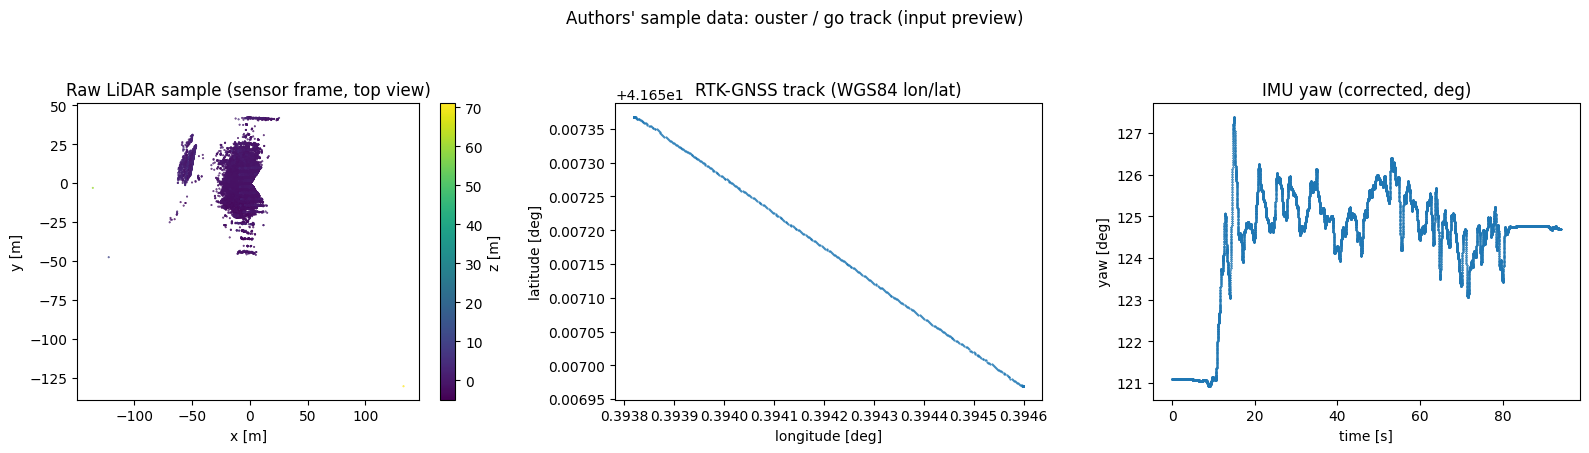

In [ ]:
import matplotlib.pyplot as plt

sub = lidar.iloc[:: max(1, len(lidar) // 300_000)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sc = axes[0].scatter(sub.x, sub.y, s=0.2, c=sub.z, cmap="viridis")
axes[0].set_title("Raw LiDAR sample (sensor frame, top view)")
axes[0].set_xlabel("x [m]"); axes[0].set_ylabel("y [m]")
plt.colorbar(sc, ax=axes[0], label="z [m]")
axes[1].plot(gnss.lon, gnss.lat, ".", ms=1)
axes[1].set_title("RTK-GNSS track (WGS84 lon/lat)")
axes[1].set_xlabel("longitude [deg]"); axes[1].set_ylabel("latitude [deg]")
axes[2].plot(imu.t - imu.t.min(), imu.yaw, ".", ms=0.5)
axes[2].set_title("IMU yaw (corrected, deg)")
axes[2].set_xlabel("time [s]"); axes[2].set_ylabel("yaw [deg]")
fig.suptitle("Authors' sample data: ouster / go track (input preview)", y=1.02)
fig.tight_layout()
plt.show()

### Run the authors' pipeline: `main.py ouster go`

Execute the authors' Python entry point exactly as documented (`python3 main.py ouster go`, working directory `python/src`), which: (1) converts GNSS lon/lat to UTM zone 31N (EPSG:25831) with pyproj, (2) splits the LiDAR file into 1,000,000-point frames, (3) drops points farther than `DIST_MAX = 4 m`, (4) applies the authors' LiDAR→GNSS lever-arm offsets, and (5) rotates each point by the interpolated IMU pitch/yaw and translates it by the interpolated GNSS position. The pipeline logs to `lidar_processing.log` and writes one `point_cloud_<frame>.txt` per frame; because the author `main()` swallows exceptions, we explicitly assert that output files exist and are non-empty.

**パイプライン実行：** 著者ドキュメント通り`main.py ouster go`を実行し、UTM変換・フレーム分割・距離フィルタ・IMU/GNSS補間による直接地理参照を行います。

In [ ]:
import subprocess, time
SRC = Path("/content/mtls/python/src")
RESULT_DIR = Path("/content/mtls/results/python/pointcloud/ouster/go")
t0 = time.time()
proc = subprocess.run([sys.executable, "main.py", "ouster", "go"], cwd=SRC, timeout=3600)
wall = time.time() - t0
print(f"exit code: {proc.returncode}   wall time: {wall/60:.1f} min")
pcd_files = sorted(RESULT_DIR.glob("point_cloud_*.txt"))
assert pcd_files and all(p.stat().st_size > 0 for p in pcd_files), "pipeline produced no point clouds"
print(f"{len(pcd_files)} point-cloud frames written to {RESULT_DIR}")
log = (SRC / "lidar_processing.log").read_text().splitlines()
print("--- lidar_processing.log (tail) ---")
print("\n".join(log[-6:]))

exit code: 0   wall time: 2.8 min
20 point-cloud frames written to /content/mtls/results/python/pointcloud/ouster/go
--- lidar_processing.log (tail) ---
2026-10-27 01:03:15,067 - INFO - Frame 19: 803755/1000000 valid points
2026-10-27 01:03:21,346 - INFO - Processed frame 19 in 6.40 seconds
2026-10-27 01:03:21,347 - INFO - Processing frame 20/20
2026-10-27 01:03:21,418 - INFO - Frame 20: 803188/999999 valid points
2026-10-27 01:03:27,973 - INFO - Processed frame 20 in 6.63 seconds
2026-10-27 01:03:27,975 - INFO - Processed 20/20 frames successfully


### Per-frame results — counts and UTM extents

Load every generated frame and build a per-frame summary: number of retained points and the min/max Easting, Northing and Altitude (UTM zone 31N, metres). This is the notebook's small results table.

**結果テーブル：** 各フレームの点数とUTM座標の範囲を示します。

In [ ]:
rows = []
for p in pcd_files:
    a = pd.read_csv(p, sep=r"\s+", skiprows=1, header=None, engine="c")
    a.columns = ["t", "frame", "easting", "northing", "altitude", "intensity"]
    rows.append({"frame": int(a.frame.iloc[0]), "points": len(a),
                 "easting_min_m": a.easting.min(), "easting_max_m": a.easting.max(),
                 "northing_min_m": a.northing.min(), "northing_max_m": a.northing.max(),
                 "altitude_min_m": a.altitude.min(), "altitude_max_m": a.altitude.max()})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"\ntotal georeferenced points: {summary.points.sum():,}")

 frame  points  easting_min_m  easting_max_m  northing_min_m  northing_max_m  altitude_min_m  altitude_max_m
     1  504021      282995.84      283003.27      4615013.11      4615020.61          261.00          262.99
    10  597775      282997.41      283005.54      4615011.57      4615019.55          260.95          264.61
    11  694046      282998.17      283006.40      4615011.06      4615019.01          260.84          264.65
    12  773769      282998.98      283007.16      4615010.60      4615018.54          260.73          264.76
    13  810633      282999.75      283007.79      4615010.00      4615018.04          260.84          264.79
    14  831650      283000.20      283008.59      4615009.48      4615017.38          260.92          264.56
    15  834905      283000.97      283009.23      4615008.92      4615016.86          260.97          264.22
    16  831519      283001.71      283010.00      4615008.41      4615016.40          260.95          264.16
    17  819174     

### Render the georeferenced orchard point cloud

3-D view (left) and top view (right) of the full georeferenced point cloud, coloured by altitude and intensity respectively, subsampled for plotting only. This is the output the paper's workflow would feed into the geometric-parameter estimation stage (tree height, width, crown cross-sectional area).

**点群の描画：** 地理参照後の点群を3次元図と俯瞰図で表示します（表示間引きのみ）。

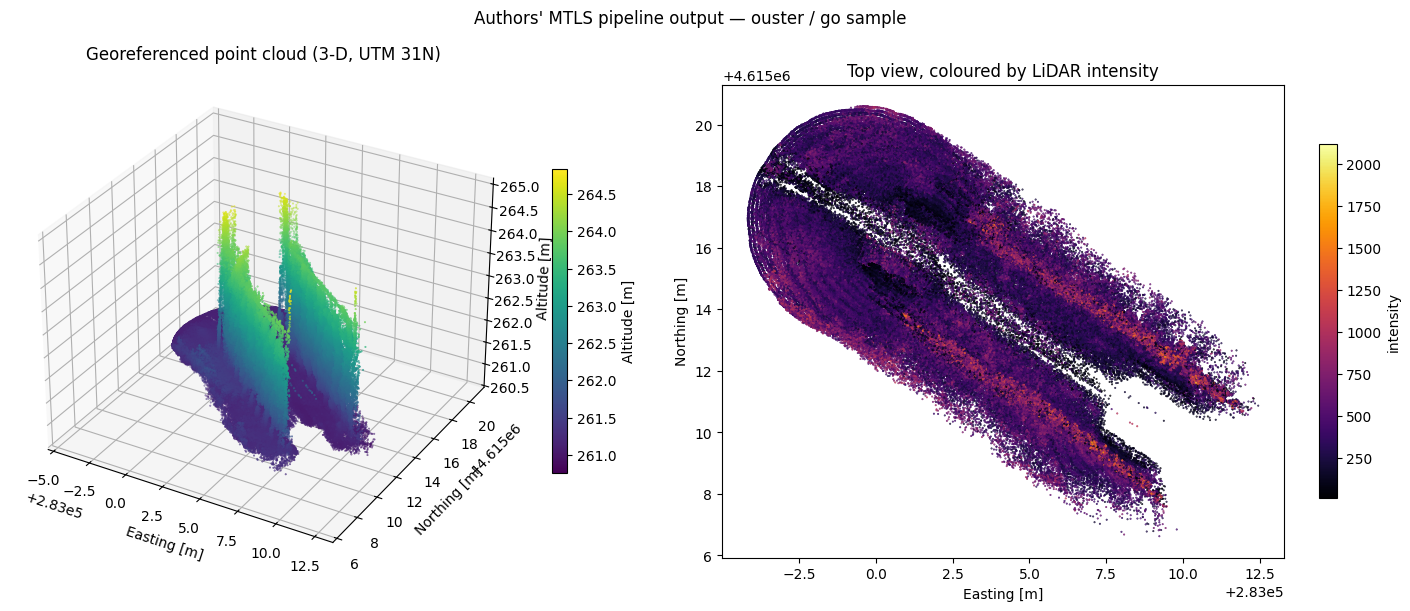

In [ ]:
frames = []
for p in pcd_files:
    a = pd.read_csv(p, sep=r"\s+", skiprows=1, header=None, engine="c")
    a.columns = ["t", "frame", "easting", "northing", "altitude", "intensity"]
    frames.append(a)
allpts = pd.concat(frames, ignore_index=True)
plotpts = allpts.iloc[:: max(1, len(allpts) // 400_000)]

fig = plt.figure(figsize=(15, 5.8))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
s1 = ax1.scatter(plotpts.easting, plotpts.northing, plotpts.altitude, s=0.2,
                 c=plotpts.altitude, cmap="viridis")
ax1.set_title("Georeferenced point cloud (3-D, UTM 31N)")
ax1.set_xlabel("Easting [m]"); ax1.set_ylabel("Northing [m]"); ax1.set_zlabel("Altitude [m]")
plt.colorbar(s1, ax=ax1, label="Altitude [m]", shrink=0.6)
ax2 = fig.add_subplot(1, 2, 2)
s2 = ax2.scatter(plotpts.easting, plotpts.northing, s=0.2, c=plotpts.intensity, cmap="inferno")
ax2.set_title("Top view, coloured by LiDAR intensity")
ax2.set_xlabel("Easting [m]"); ax2.set_ylabel("Northing [m]")
ax2.set_aspect("equal")
plt.colorbar(s2, ax=ax2, label="intensity", shrink=0.7)
fig.suptitle("Authors' MTLS pipeline output — ouster / go sample", y=1.0)
fig.tight_layout()
plt.show()

### Export the per-frame summary (CSV)

Save the per-frame table next to the generated clouds so it can be inspected or downloaded from Colab without re-running the pipeline.

**CSV出力：** フレーム別サマリをCSVとして保存します。

In [ ]:
out_csv = "/content/mtls/results/ouster_go_frame_summary.csv"
summary.to_csv(out_csv, index=False)
print("saved:", out_csv, f"({len(summary)} rows)")
display(summary.head(8))

saved: /content/mtls/results/ouster_go_frame_summary.csv (20 rows)


,frame,points,easting_min_m,easting_max_m,northing_min_m,northing_max_m,altitude_min_m,altitude_max_m
0,1,504021,282995.835339,283003.265917,4.615013e+06,4.615021e+06,261.004636,262.985979
1,10,597775,282997.410618,283005.536425,4.615012e+06,4.615020e+06,260.953532,264.605663
2,11,694046,282998.168926,283006.404567,4.615011e+06,4.615019e+06,260.840944,264.649194
3,12,773769,282998.975081,283007.162954,4.615011e+06,4.615019e+06,260.727242,264.760767
4,13,810633,282999.749800,283007.791635,4.615010e+06,4.615018e+06,260.843496,264.791475
5,14,831650,283000.198847,283008.592917,4.615009e+06,4.615017e+06,260.921327,264.557958
6,15,834905,283000.968166,283009.230278,4.615009e+06,4.615017e+06,260.972185,264.223203
7,16,831519,283001.714970,283009.995437,4.615008e+06,4.615016e+06,260.951111,264.157635


## Interpretation, differences from the paper, and limitations

- **What was validated:** the authors' own Python implementation, running on the authors' own sample acquisition (`ouster/go`), produces a georeferenced UTM point cloud of the apple-tree row (EPSG:25831) with the documented lever-arm offsets, 4 m range filter, and IMU pitch/yaw + GNSS position interpolation. Frame counts, bounds and wall time above are the actual observed outputs of this run.
- **What was NOT executed:** the LIO-SAM SLAM reconstruction stage (requires ROS1 Noetic + GTSAM + catkin build and the multi-GB rosbags on the authors' SharePoint share, whose anonymous availability is unconfirmed); and the Viametris ground-truth comparison (`compute_metrics.py` needs `../geometry/*_go.txt` tables that the repository does not include). Consequently no tree height/width/cross-sectional-area error metrics are computed here.
- **Deviations from the authors' scripts:** the two `main()` call-signature fixes shown above, and skipping `read_rosbag.py`/`correct_imu_yaw.py` (ROS-only rosbag conversion already done by the authors for the sample files). No parameter, offset, filter threshold or transform was altered.
- **Scope caution:** the sample LiDAR file contains ≈20 % of captured points and a single-example run does not verify any published accuracy figure of the paper.

**留意点：** 本ノートブックは点群生成段階のみを検証します。SLAM再構築や幾何パラメータ精度比較は実行していません。サンプルは全点の約20%です。

## References & documented (not executed) SLAM rerun procedure

- Paper: [DOI 10.1117/12.3085863](https://doi.org/10.1117/12.3085863) — SPIE Proc. 13666, 136661V (2025).
- Authors' reproducibility package: [GRAP-UdL-AT/LIO-SAM-orchard-reconstruction](https://github.com/GRAP-UdL-AT/LIO-SAM-orchard-reconstruction) @ `944e9ba` (BSD-3-Clause) — provides `config/params_ouster.yaml`, `config/params_livox.yaml`, `launch/run_orchard.launch` for upstream LIO-SAM.
- Upstream algorithm: [TixiaoShan/LIO-SAM](https://github.com/TixiaoShan/LIO-SAM) (BSD-3-Clause), Shan et al., *LIO-SAM: Tightly-coupled Lidar Inertial Odometry via Smoothing and Mapping*, IROS 2020.
- Point-cloud generation code used here: [GRAP-UdL-AT/MTLS_point_cloud_generation_imu](https://github.com/GRAP-UdL-AT/MTLS_point_cloud_generation_imu) @ `3838ce9`.

For reference — the authors' documented SLAM rerun (not executed in this notebook, needs a local ROS1 Noetic workspace and the rosbag dataset):

```bash
cd ~/catkin_ws/src && git clone https://github.com/TixiaoShan/LIO-SAM.git && cd .. && catkin_make
# copy the authors' config + launch files from GRAP-UdL-AT/LIO-SAM-orchard-reconstruction
roslaunch lio_sam run_orchard.launch config_file:=params_ouster.yaml
rosbag play /path/to/ouster_dataset.bag
```